# 16 - Borehole Image (FMI) Processing

**Part B - Petrophys Curriculum**

A Formation MicroImager (FMI) is not an ordinary scalar log. Instead of one value per
depth, each depth samples the borehole wall with **many microresistivity buttons** spread
across a set of pads and flaps. The raw recording is a strip of *buttons*, not a picture:
its columns are sensor positions on the tool, not compass directions. A recognisable
image only appears once every button is **rotated to its true azimuth** using the tool's
navigation curve and then contrast-enhanced (equalized).

This notebook walks through the `petrophys.imaging` FMI pipeline end to end.

## Learning goals

- Understand what an FMI records: pads/flaps, buttons, and the `P1AZ` navigation curve.
- Load image logs with `read_borehole_image_las` / `read_borehole_image_dlis` /
  `read_fmi_dlis`, and hold them in a `BoreholeImageData` container.
- Attach well navigation (`with_navigation`) and rotate buttons to compass azimuth
  (`orient_to_azimuth`) - the step that turns a strip into an image.
- Contrast-enhance with **static** vs **dynamic** equalization
  (`equalize_static` / `equalize_dynamic`) and know when to pick which.
- Measure `azimuthal_coverage` and display with `plot_fmi` /
  `visualization.create_fmi_panel`.

## Why this matters

FMI images are the primary tool for **structural and sedimentological dip picking**:
a planar bed or fracture that cuts the borehole at an angle projects onto the unrolled
0-360 degree image as a **sinusoid**. The amplitude of that sinusoid encodes dip
magnitude and its trough points down-dip azimuth. None of this is visible in the raw
per-button strip - it emerges only after orientation. Equalization then trades
large-scale contrast against fine textural detail so an interpreter can see both thick
units and thin laminae.

### Prerequisites

This notebook assumes you are comfortable with `read_las` and the `Well`/`Curve` model
from the Part A foundations notebooks. No prior imaging knowledge is required.

> **Data note.** The petrophys package does **not** bundle a real FMI DLIS file (those
> are hundreds of MB). The legacy notebook `notebooks/legacy/14_fmi_pads_to_oriented_image.ipynb`
> reads one via the `PETROPHYS_FMI_DLIS` environment variable. To keep this tutorial
> self-contained and reproducible, we **construct a small synthetic pad/button array**
> with a known dipping bed. It is clearly flagged as *illustrative* wherever it appears,
> and it exercises exactly the same public API you would call on a real tool.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt

import petrophys
from petrophys.imaging import (
    BoreholeImageData,
    read_borehole_image_las,
    read_borehole_image_dlis,
    read_fmi_dlis,
    with_navigation,
    get_navigation,
    orient_to_azimuth,
    equalize_static,
    equalize_dynamic,
    azimuthal_coverage,
    plot_fmi,
    fmi_colormap,
)
from petrophys.imaging.fmi import ARRAY_ORDER, ARRAY_OFFSET_DEG, ARRAY_SPACING_DEG
from petrophys.visualization import create_fmi_panel

print("petrophys", petrophys.__version__)
print("FMI array order (pads/flaps):", ARRAY_ORDER)
print("array spacing:", ARRAY_SPACING_DEG, "deg  (8 arrays around 360 deg)")
print("array azimuth offsets from pad 1:")
for name, off in ARRAY_OFFSET_DEG.items():
    print("  %-5s -> %5.1f deg" % (name, off))

petrophys 0.1.0
FMI array order (pads/flaps): ('FMPA', 'FMFA', 'FMPB', 'FMFB', 'FMPC', 'FMFC', 'FMPD', 'FMFD')
array spacing: 45.0 deg  (8 arrays around 360 deg)
array azimuth offsets from pad 1:
  FMPA  ->   0.0 deg
  FMFA  ->  45.0 deg
  FMPB  ->  90.0 deg
  FMFB  -> 135.0 deg
  FMPC  -> 180.0 deg
  FMFC  -> 225.0 deg
  FMPD  -> 270.0 deg
  FMFD  -> 315.0 deg


## 1. How the readers map onto data sources

`petrophys.imaging` offers three entry points, all returning a `BoreholeImageData`:

| Function | Source | Typical use |
| --- | --- | --- |
| `read_fmi_dlis(path)` | processed FMI DLIS | **preferred** - reads image channels *and* navigation (`P1AZ`, `HAZI`, `DEVI`, `RB`), interpolating nav onto image depth |
| `read_borehole_image_dlis(path)` | any image DLIS frame | generic electrical/acoustic image, auto-detects array channels |
| `read_borehole_image_las(path)` | flattened LAS export | LAS can't hold DLIS arrays, so buttons arrive as `FMPA_0 ... FMPA_23`; this regroups them into a 2D image |

Because no DLIS ships with the package, the calls below simply **show the signatures** you
would use. The rest of the notebook then builds a `BoreholeImageData` by hand so every
downstream step runs live.

In [2]:
# The real-data one-liners (not executed here - no bundled DLIS):
usage = '''
# Preferred: processed FMI DLIS (image + navigation together)
data = read_fmi_dlis("/path/to/well_FMI.dlis")

# Generic image DLIS frame
data = read_borehole_image_dlis("/path/to/image.dlis", image_channels=["FMPA", "FMFA"])

# Flattened LAS export (buttons as FMPA_0 ... FMPA_23):
data = read_borehole_image_las("/path/to/fmi_buttons.las")
'''
print(usage)
print("All three return a BoreholeImageData with .depth, .image, .channel_names, ...")


# Preferred: processed FMI DLIS (image + navigation together)
data = read_fmi_dlis("/path/to/well_FMI.dlis")

# Generic image DLIS frame
data = read_borehole_image_dlis("/path/to/image.dlis", image_channels=["FMPA", "FMFA"])

# Flattened LAS export (buttons as FMPA_0 ... FMPA_23):
data = read_borehole_image_las("/path/to/fmi_buttons.las")

All three return a BoreholeImageData with .depth, .image, .channel_names, ...


## 2. Build an illustrative pad/button array

> **ILLUSTRATIVE SYNTHETIC DATA** - this is not a real well. We simulate an 8-array FMI
> (`FMPA ... FMFD`, 4 pads + 4 flaps) with 12 buttons per array = 96 raw columns over a
> 10 m interval.

Two physical effects are baked in so the later steps have something real to reveal:

1. **Tool rotation.** As the tool travels up-hole it slowly rotates, so `P1AZ`
   (the compass azimuth of pad 1) ramps with depth. This is why raw buttons are
   meaningless until oriented.
2. **A dipping bed.** A planar conductive marker crosses the borehole at a dip. Its
   apparent depth on each button is shifted by `amp * cos(azimuth - strike)` - the
   sinusoid signature we expect to recover after orientation.

In [3]:
rng = np.random.default_rng(0)

n_depth = 400
buttons_per_array = 12
depth = np.linspace(3000.0, 3010.0, n_depth)      # 10 m, ~0.025 m sampling

names = list(ARRAY_ORDER)                          # FMPA, FMFA, ... FMFD
widths = [buttons_per_array] * len(names)          # 12 buttons each -> 96 columns

# (1) Tool slowly rotates with depth: pad-1 azimuth ramps 0 -> 120 deg.
p1az = np.mod(np.linspace(0.0, 120.0, n_depth), 360.0)

# (2) A dipping conductive bed. Buttons within a pad span a small arc.
dip_amplitude_m = 1.2
strike_rad = np.deg2rad(60.0)
half_arc_deg = 0.5 * ARRAY_SPACING_DEG * 0.70      # 70% pad arc, matching the library default

columns = []
for name in names:
    offset = ARRAY_OFFSET_DEG[name]
    local = np.linspace(-half_arc_deg, half_arc_deg, buttons_per_array)
    # absolute azimuth of every button at every depth
    button_az = np.deg2rad(np.mod(p1az[:, None] + offset + local[None, :], 360.0))
    # dipping plane -> apparent depth shift per button
    apparent_depth = depth[:, None] + dip_amplitude_m * np.cos(button_az - strike_rad)
    marker = np.exp(-((np.mod(apparent_depth, 3.0) - 1.5) ** 2) / 0.03)  # conductive bands
    background = 0.5 + 0.15 * np.sin(apparent_depth * 2.0)
    response = background - 0.4 * marker + 0.03 * rng.standard_normal(apparent_depth.shape)
    columns.append(response.astype(np.float32))

raw_image = np.concatenate(columns, axis=1)
print("raw image shape (depth x buttons):", raw_image.shape)
print("expected columns = %d arrays x %d buttons = %d"
      % (len(names), buttons_per_array, len(names) * buttons_per_array))

raw image shape (depth x buttons): (400, 96)
expected columns = 8 arrays x 12 buttons = 96


### Wrap it in a `BoreholeImageData` and attach navigation

`BoreholeImageData.from_arrays` is the constructor the DLIS/LAS readers ultimately call.
It records which columns belong to which array via `samples_per_channel`, so the
orientation step knows each array's fixed azimuthal offset. We then attach the `P1AZ`
navigation curve with `with_navigation`; `orient_to_azimuth` reads it back out with
`get_navigation`.

In [4]:
data = BoreholeImageData.from_arrays(
    depth=depth,
    image=raw_image,
    channel_names=names,
    samples_per_channel=widths,
    image_type="fmi_raw",
    depth_unit="m",
)
data = with_navigation(data, {"P1AZ": p1az})

print("n depth samples   :", data.n_samples)
print("n borehole samples:", data.n_borehole_samples)
print("channels          :", data.channel_names)
print("depth range       : %.1f - %.1f %s" % (data.top, data.bottom, data.depth_unit))
print("navigation curves :", sorted(get_navigation(data)))

n depth samples   : 400
n borehole samples: 96
channels          : ['FMPA', 'FMFA', 'FMPB', 'FMFB', 'FMPC', 'FMFC', 'FMPD', 'FMFD']
depth range       : 3000.0 - 3010.0 m
navigation curves : ['P1AZ']


## 3. The raw strip is not an image

Plot the raw button array as-is. The x-axis is a **borehole sample index**, not a
compass direction. Because the tool rotates with depth, the same physical feature drifts
sideways as you go down - there is no coherent sinusoid, just smeared bands.

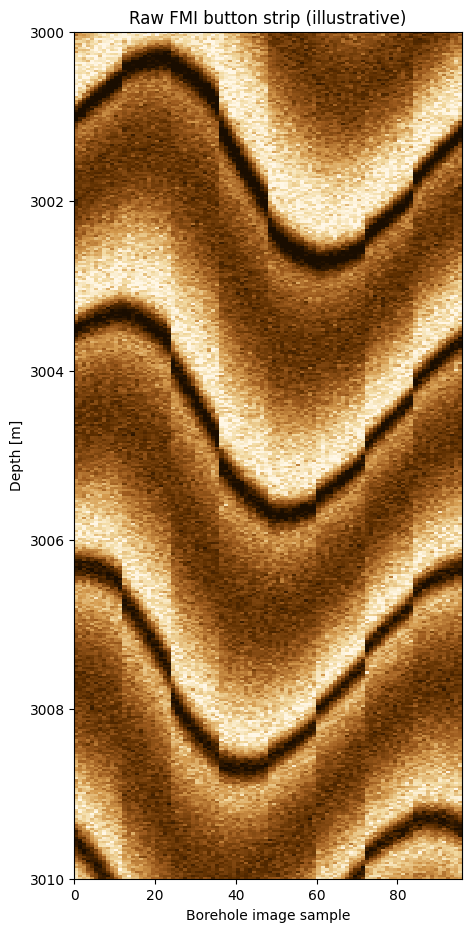

In [5]:
# The raw (un-oriented) strip, rendered by the library's plot_fmi. With static
# equalization and an un-oriented image, plot_fmi labels the x-axis as the
# borehole sample index (NOT a compass direction) - exactly the point here.
ax = plot_fmi(data, equalize="static", interpolation="nearest")
ax.set_title("Raw FMI button strip (illustrative)")
plt.show()

## 4. Orient to azimuth: the key step

`orient_to_azimuth` rotates every button to its true compass azimuth using the
navigation reference (`reference="north"` uses `P1AZ`; `reference="highside"` uses `RB`)
plus each array's fixed offset, then bins the buttons onto a regular 0-360 degree grid.

Crucially, the wedges **between** pads are never imaged, so they are left as `NaN`
(gaps) rather than interpolated - the picture reflects real borehole-wall coverage.
The output is a new `BoreholeImageData` whose single logical channel is `AZIMUTH`.

In [6]:
oriented = orient_to_azimuth(data, n_azimuth=180, reference="north")

print("oriented image shape:", oriented.image.shape, "(depth x azimuth bins)")
print("image_type          :", oriented.image_type)
print("oriented flag        :", oriented.metadata.get("oriented"))
print("orientation ref      :", oriented.metadata.get("orientation_reference"))
print("arrays used          :", oriented.metadata.get("used_arrays"))

oriented image shape: (400, 180) (depth x azimuth bins)
image_type          : fmi_oriented
oriented flag        : True
orientation ref      : north
arrays used          : ['FMPA', 'FMFA', 'FMPB', 'FMFB', 'FMPC', 'FMFC', 'FMPD', 'FMFD']


Now plot the oriented image with `plot_fmi`. The x-axis carries a **compass scale**
(N-E-S-W-N) and the dipping bed appears as the classic **sinusoid**. Its trough points
toward the down-dip azimuth; its peak-to-trough amplitude scales with dip.

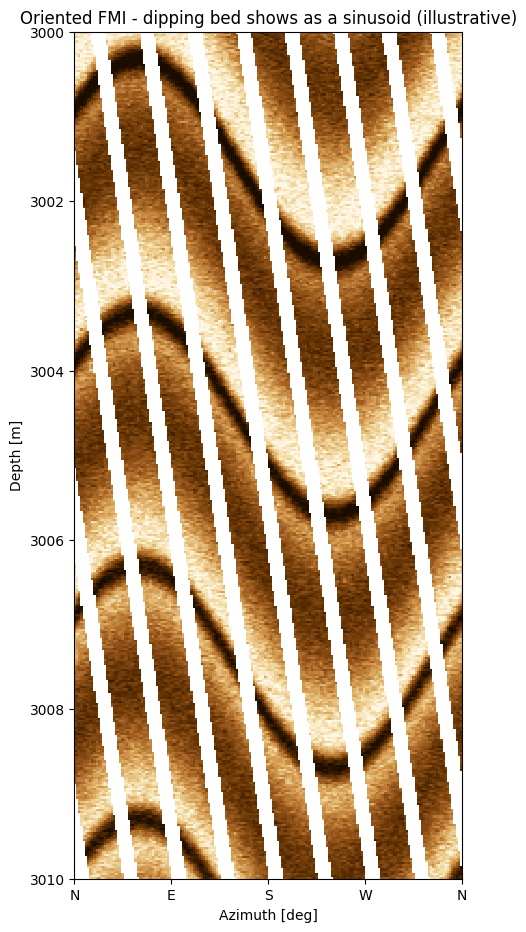

In [7]:
# plot_fmi detects the oriented image and draws a compass (N-E-S-W-N) x-axis.
ax = plot_fmi(oriented, equalize="static", interpolation="nearest")
ax.set_title("Oriented FMI - dipping bed shows as a sinusoid (illustrative)")
plt.show()

### Azimuthal coverage

`azimuthal_coverage` reports, per depth, the fraction of the 360 degrees actually imaged.
With 8 arrays covering ~70% of their local arcs, we expect roughly 70% coverage; the
un-imaged inter-pad wedges are the missing fraction. Real FMI in gauge hole behaves the
same way - full-circle coverage is never achieved by a pad tool.

azimuthal coverage: mean=0.70  min=0.69  max=0.71


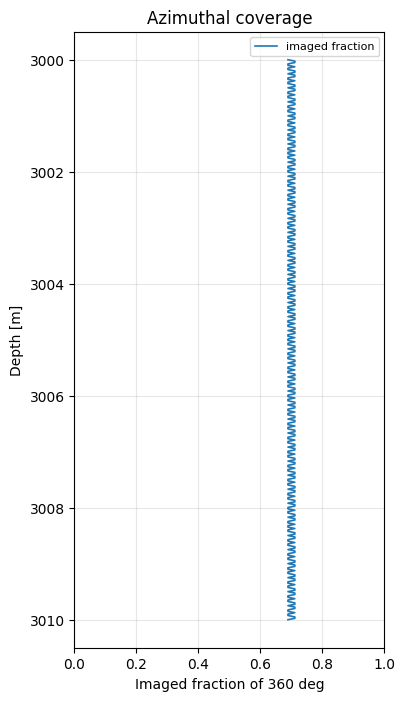

In [8]:
from petrophys.visualization import create_line_comparison

coverage = azimuthal_coverage(oriented)
print("azimuthal coverage: mean=%.2f  min=%.2f  max=%.2f"
      % (np.nanmean(coverage), np.nanmin(coverage), np.nanmax(coverage)))

# Coverage vs depth: x = imaged fraction, series = depth, y-axis inverted so
# shallow sits at the top (depth-style view).
fig, ax = create_line_comparison(
    coverage, {"imaged fraction": oriented.depth},
    xlabel="Imaged fraction of 360 deg", ylabel="Depth [m]",
    title="Azimuthal coverage", figsize=(4, 8), invert_yaxis=True,
)
ax.set_xlim(0, 1)
plt.show()

## 5. Static vs dynamic equalization

The oriented image still needs contrast enhancement. Two schemes:

- **Static** (`equalize_static`): one percentile clip/stretch applied to the *whole*
  interval. Preserves large-scale contrast (you can compare a resistive unit near the top
  with a conductive one near the bottom), but subtle thin-bed texture can wash out.
- **Dynamic** (`equalize_dynamic`): a **sliding-window** percentile stretch along depth.
  Re-normalises locally, so faint laminae and thin beds pop - at the cost of losing
  absolute contrast between distant intervals.

Both map finite values to 0-1; `NaN` gaps stay transparent. Rule of thumb: static for
structural/large-scale work, dynamic for sedimentary texture and thin-bed detail.

static  : finite fraction = 0.70
dynamic : finite fraction = 0.70  (window = 0.5 m)


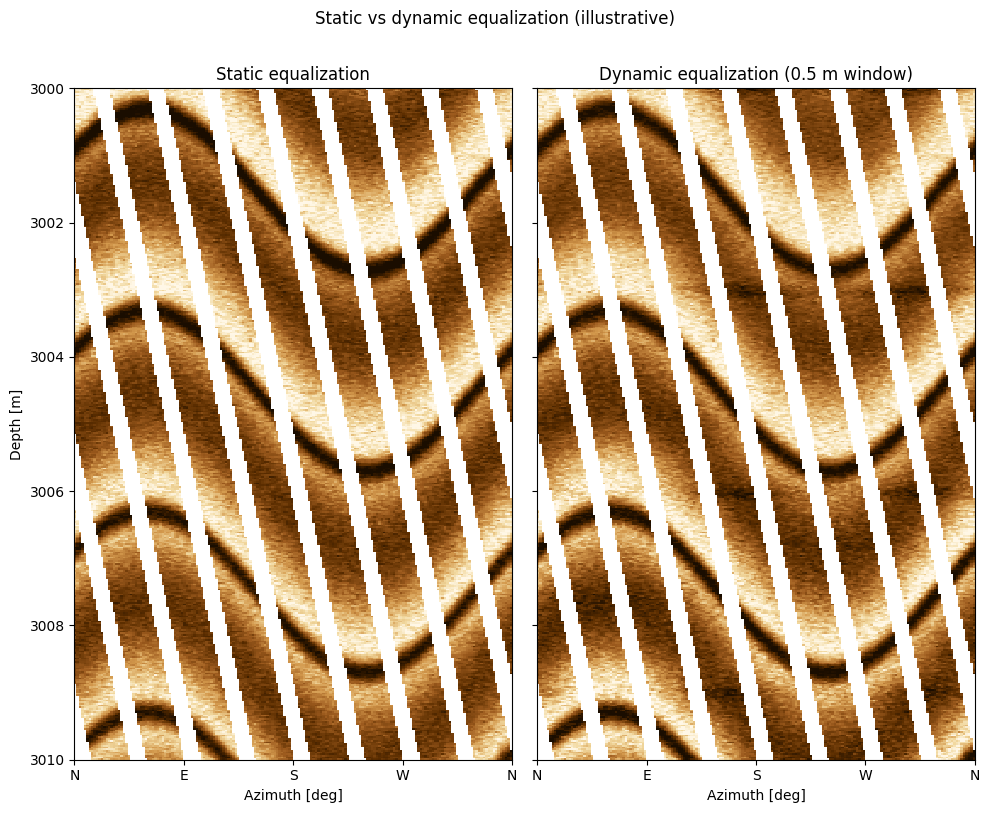

In [9]:
static_img = equalize_static(oriented.image)
dynamic_img = equalize_dynamic(oriented.image, oriented.depth, window_m=0.5)

print("static  : finite fraction = %.2f" % np.isfinite(static_img).mean())
print("dynamic : finite fraction = %.2f  (window = 0.5 m)" % np.isfinite(dynamic_img).mean())

# Render both with the library's plot_fmi so the image display stays in
# petrophys.imaging; equalize= selects the scheme internally.
fig, axes = plt.subplots(1, 2, figsize=(10, 8), sharey=True)
plot_fmi(oriented, ax=axes[0], equalize="static", interpolation="nearest")
axes[0].set_title("Static equalization")
plot_fmi(oriented, ax=axes[1], equalize="dynamic", window_m=0.5, interpolation="nearest")
axes[1].set_title("Dynamic equalization (0.5 m window)")
axes[1].set_ylabel("")
fig.suptitle("Static vs dynamic equalization (illustrative)", y=1.01)
plt.tight_layout()
plt.show()

## 6. One-call panel: `create_fmi_panel`

For a quick look, `petrophys.visualization.create_fmi_panel` wraps the whole thing:
pass the **raw** (un-oriented) `BoreholeImageData` with `orient=True` and it will detect
the navigation curve, orient internally, equalize, and render a titled figure. Passing
`orient=False` shows the raw strip. `equalize` selects `"static"`, `"dynamic"`, or
`"none"`.

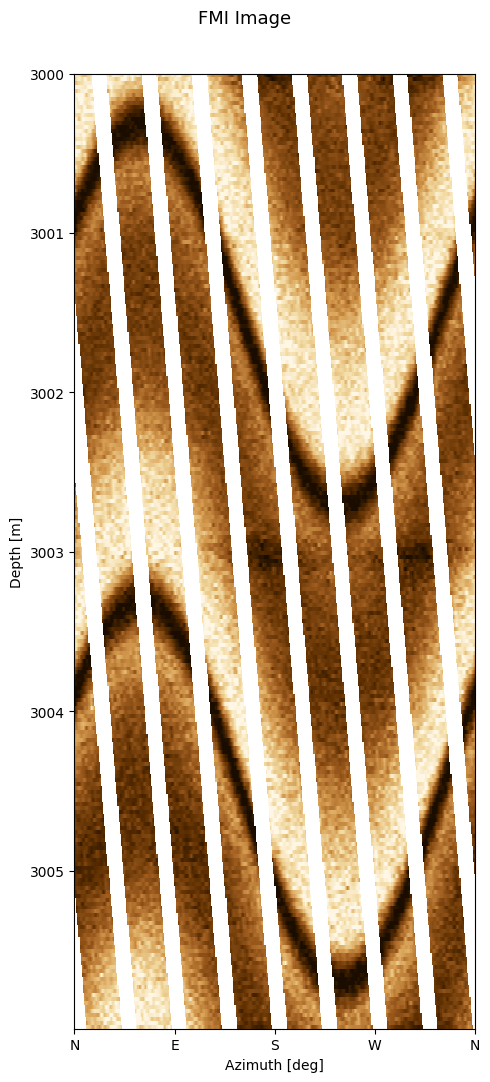

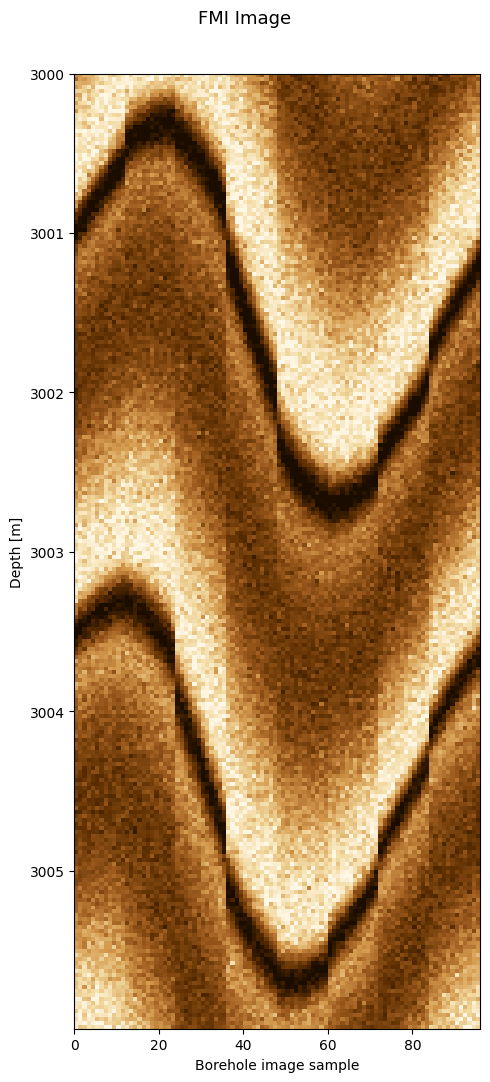

In [10]:
# Oriented + dynamic, restricted to a 4 m window
create_fmi_panel(data, depth_range=(3000.0, 3006.0), orient=True, equalize="dynamic")
plt.show()

# Raw (un-oriented) for contrast
create_fmi_panel(data, depth_range=(3000.0, 3006.0), orient=False, equalize="static")
plt.show()

## Pitfalls & parameter choices

- **Orientation needs navigation.** `orient_to_azimuth(reference="north")` requires
  `P1AZ`; `reference="highside"` requires `RB`. `read_fmi_dlis` loads these for you and
  interpolates them onto image depth. If you build data by hand, attach them with
  `with_navigation` or orientation raises.
- **Gaps are real, not missing.** Inter-pad wedges stay `NaN` on purpose. Do not
  in-fill them before dip picking - the empty azimuths are genuine no-coverage.
- **`n_azimuth` is a display grid, not resolution.** Choosing 360 vs 180 bins only sets
  how finely buttons are re-binned; it cannot create coverage the tool never recorded.
- **Static vs dynamic is a trade, not a ranking.** Static keeps absolute contrast;
  dynamic surfaces texture. Interpreters routinely view both.
- **`read_borehole_image_las` regroups flattened curves** (`FMPA_0..FMPA_23`); make sure
  the exporter used a consistent `PREFIX_index` naming or pass `channel_prefixes`.

## Recap

- An FMI records microresistivity **buttons on pads/flaps**, not compass-referenced
  pixels; the raw strip is not yet an image.
- `BoreholeImageData` holds depth, the 2D button array, and which columns belong to which
  array - everything `orient_to_azimuth` needs.
- **Orientation** (`orient_to_azimuth`, using `P1AZ` + fixed offsets) is what turns the
  strip into a compass-referenced image where a dipping bed reads as a **sinusoid**.
- **Equalization** (`equalize_static` vs `equalize_dynamic`) tunes contrast; **coverage**
  (`azimuthal_coverage`) tells you how much of the wall was actually seen.
- `plot_fmi` and `create_fmi_panel` render the result in one call.

## Try it yourself

> **Exercise 1.** Change `dip_amplitude_m` (say 0.4 vs 2.0) and re-orient. How does the
> sinusoid amplitude on the oriented image respond, and what does that say about dip?
>
> **Exercise 2.** Rotate the tool faster by widening the `p1az` ramp (e.g. 0 -> 360).
> Confirm the *raw* strip degrades further while the *oriented* image is unchanged -
> orientation removes tool rotation.
>
> **Exercise 3.** Re-run `orient_to_azimuth` with `n_azimuth=90` and again with `360`.
> Compare `azimuthal_coverage` - does more bins buy more coverage? Why not?

## What's next

Continue with **17_visualization_masterclass.ipynb**, where `create_fmi_panel` takes its
place alongside the full petrophys plotting gallery: template log viewers, triple combo,
the crossplot family, and specialist NMR/flow-unit panels.